# Exploratory data analysis

Project 18: inspect the supplied water-quality data before fitting a model. This notebook requires the combined raw CSV. Restore it with `python scripts/download_data.py`. The target is the authors' calculated index, so interpretation depends on its provenance.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'configs/default.json').exists() else Path.cwd().parent
REPORTS = ROOT / 'reports'
config = json.loads((ROOT / 'configs/default.json').read_text())


## 1. Load and inspect the actual source file

The combined CSV is the single source. Country CSVs are alternate views, not extra observations.

In [2]:
from water_quality.data import read_dataset, FEATURES, TARGET
df = read_dataset(ROOT / config['data'])
print('Shape:', df.shape)
display(df.head())
display(df.Country.value_counts().rename('Rows'))

Shape: (2827977, 14)


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
0,Canada,SE649035-145565,River,12-01-1974,0.059248,1.30,8.1500,0.011917,8.07500,9.885,0.343917,11.73155,100.0,Excellent
1,Canada,SE649035-145565,River,12-01-1975,0.039821,1.38,7.8000,0.009417,7.73333,10.150,0.449083,11.82009,100.0,Excellent
2,Canada,SE649035-145565,River,12-01-1976,0.031341,2.23,7.8000,0.011000,7.46667,10.235,0.220750,14.87472,100.0,Excellent
3,Canada,SE649035-145565,River,12-01-1977,0.020501,1.61,8.1500,0.012333,7.78333,11.116,0.572250,15.89293,100.0,Excellent
4,Canada,SE649035-145565,River,12-01-1978,0.020023,1.64,4.3708,0.006182,7.10000,7.068,0.371091,15.22888,100.0,Excellent


Country
England    2129198
USA         413814
Ireland     235019
China        45997
Canada        3949
Name: Rows, dtype: int64

## 2. Missingness, ranges and duplicates

No empty cell does not mean no upstream imputation. Preserve extreme pollution events and inspect units rather than deleting every IQR outlier.

In [3]:
display(df.isna().sum().rename('Empty cells'))
display(df[FEATURES + [TARGET]].describe().T)
print('Exact duplicates:', df.duplicated().sum())
print('Most frequent readings:')
for column in FEATURES:
    mode = df[column].value_counts().head(1)
    print(column, mode.to_dict())

Exact duplicates: 9971
Most frequent readings:
Ammonia (mg/l) {0.03: 526716}
Biochemical Oxygen Demand (mg/l) {2.7: 686753}
Dissolved Oxygen (mg/l) {10.2: 893535}
Orthophosphate (mg/l) {0.144: 444309}
pH (ph units) {7.78: 367499}
Temperature (cel) {11.46: 311639}
Nitrogen (mg/l) {5.0: 409140}
Nitrate (mg/l) {4.5: 716630}


Country                             0
Area                                0
Waterbody Type                      0
Date                                0
Ammonia (mg/l)                      0
Biochemical Oxygen Demand (mg/l)    0
Dissolved Oxygen (mg/l)             0
Orthophosphate (mg/l)               0
pH (ph units)                       0
Temperature (cel)                   0
Nitrogen (mg/l)                     0
Nitrate (mg/l)                      0
CCME_Values                         0
CCME_WQI                            0
Name: Empty cells, dtype: int64

,count,mean,std,min,25%,50%,75%,max
Ammonia (mg/l),2827977.0,1.171360,5.668927,-0.005000,0.030000,0.05500,0.317,200.0
Biochemical Oxygen Demand (mg/l),2827977.0,4.886554,16.413632,-2.000000,1.600000,2.70000,2.830,255.0
Dissolved Oxygen (mg/l),2827977.0,10.007978,1.851052,0.000000,9.860000,10.20000,11.000,20.0
Orthophosphate (mg/l),2827977.0,0.710466,2.089436,-0.004000,0.040000,0.10700,0.227,100.0
pH (ph units),2827977.0,7.735931,0.494687,-1.000000,7.550000,7.78000,8.000,30.0
Temperature (cel),2827977.0,11.839341,5.010197,-5.260000,8.990000,11.46000,14.200,98.0
Nitrogen (mg/l),2827977.0,5.209531,6.200423,0.000000,0.780000,4.00000,6.320,46.0
Nitrate (mg/l),2827977.0,4.766794,6.073781,0.000000,1.173000,4.50000,4.940,155.0
CCME_Values,2827977.0,85.046683,17.646646,31.304144,77.153493,90.59609,100.000,100.0


## 3. Representation and metadata

England dominates the sample. Area is a coarse proxy for a site. A temporal split does not prove unseen-site generalization.

Date range: 1940-01-02 00:00:00 2023-12-17 00:00:00
Invalid dates: 0


Country
Canada      2354
China          1
England    48642
Ireland     9737
USA          955
Name: Distinct Area labels, dtype: int64

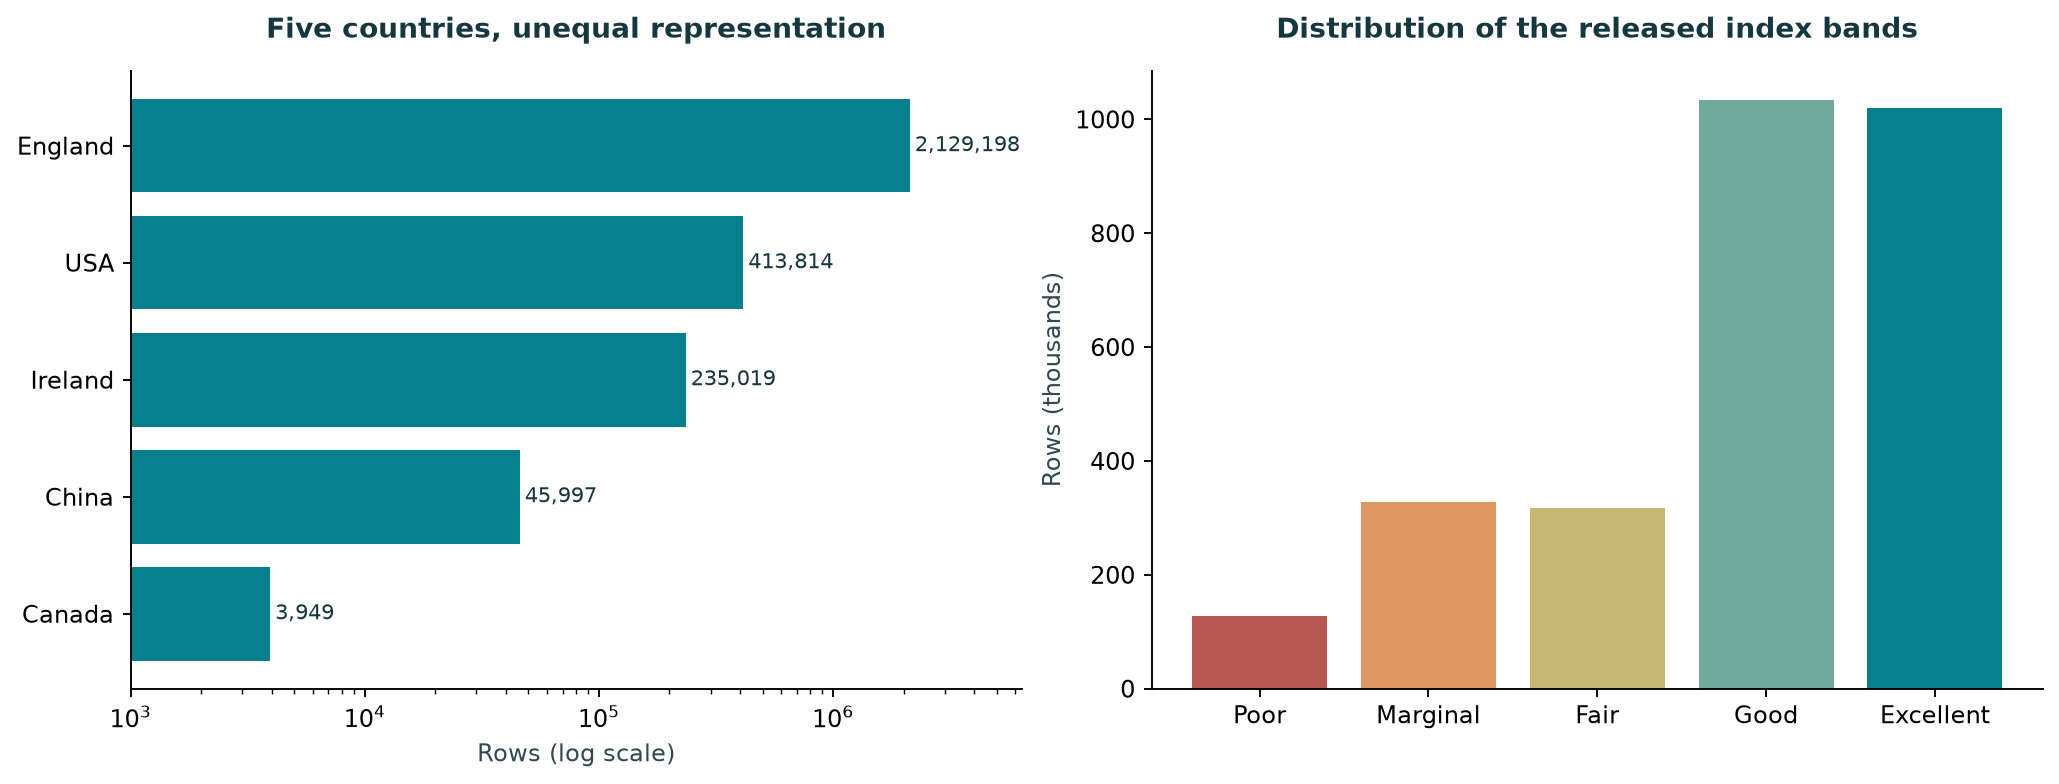

In [4]:
dates = pd.to_datetime(df.Date, format='%d-%m-%Y', errors='coerce')
print('Date range:', dates.min(), dates.max())
print('Invalid dates:', dates.isna().sum())
display(df.groupby('Country').Area.nunique().rename('Distinct Area labels'))
display(Image(filename=str(REPORTS / 'figures/data_overview.png')))

## 4. Audit the target formula

The reconstruction is a provenance check. It is deliberately separate from trained-model performance. The exact denominator is 12 and all tests use upper objectives.

In [5]:
from water_quality.data import source_formula, quality_features
error = np.abs(source_formula(df) - df[TARGET].to_numpy())
print('Matching within 1e-7:', (error < 1e-7).mean())
print('Maximum difference:', error.max())
display(quality_features(df)[FEATURES].isna().sum().rename('Missing or flagged'))

Matching within 1e-7: 1.0
Maximum difference: 2.842170943040401e-14


Ammonia (mg/l)                         2
Biochemical Oxygen Demand (mg/l)       2
Dissolved Oxygen (mg/l)                0
Orthophosphate (mg/l)                 10
pH (ph units)                        505
Temperature (cel)                   5980
Nitrogen (mg/l)                        0
Nitrate (mg/l)                         0
Name: Missing or flagged, dtype: int64

## 5. Decisions

Use one continuous target. Exclude the redundant class label and metadata from features. Remove exact duplicates, keep pollution extremes and use chronological partitions. Document the derived-target limitation.

In [6]:
audit = json.loads((REPORTS / 'data_audit.json').read_text())
assert len(df) == audit['raw_rows']
assert (error < 1e-7).all()
print('EDA and stored audit agree.')

EDA and stored audit agree.
